# Importing Files

In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
from sklearn.preprocessing import StandardScaler

# Loading the CSV File

In [49]:
df = pd.read_csv("/home/raven/Downloads/IST-Assignment/ML_Project_Submission/Data_file - 2.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# Basic exploration

In [50]:
print(df.shape)

df.info()

df.describe()

print(df.isnull().sum())

(7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null

# Churn Distribution

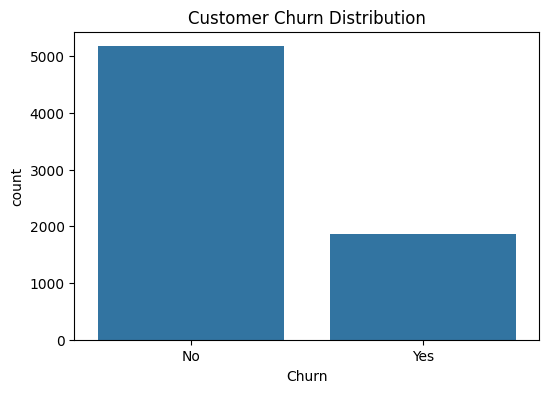

In [51]:
plt.figure(figsize=(6,4))
sns.countplot(x='Churn', data=df)
plt.title("Customer Churn Distribution")
plt.show()

# Contract vs Churn

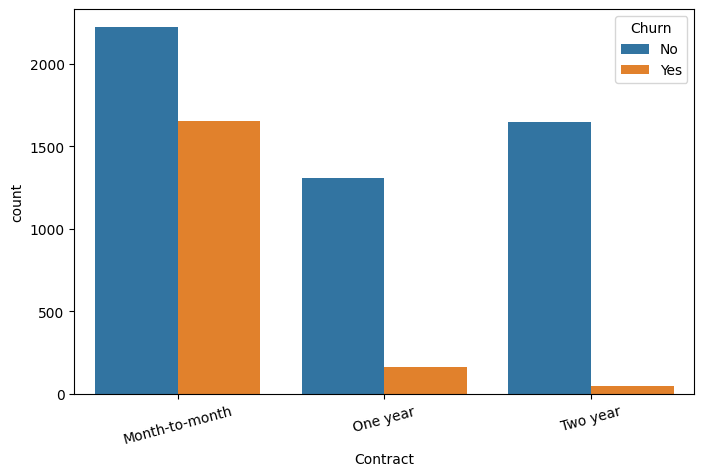

In [52]:
plt.figure(figsize=(8,5))
sns.countplot(x='Contract', hue='Churn', data=df)
plt.xticks(rotation=15)
plt.show()

# Monthly Charges Distribution

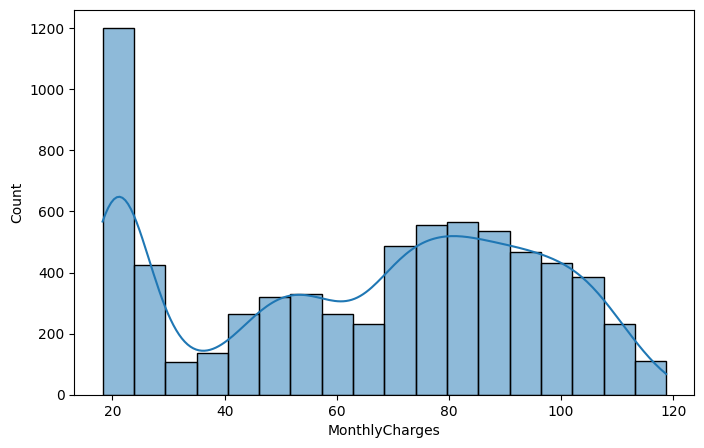

In [53]:
plt.figure(figsize=(8,5))
sns.histplot(df['MonthlyCharges'], kde=True)
plt.show()

# IMPORTANT PREPROCESSING STEP

In [54]:
print(df['TotalCharges'].dtype)

float64


# Drop Customer ID

In [55]:
df.drop('customerID', axis=1, inplace=True)

In [56]:
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce'
)

In [57]:
df['TotalCharges'] = df['TotalCharges'].fillna(
    df['TotalCharges'].median()
)

# Encode Categorical Variables

In [58]:
le = LabelEncoder()

for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = le.fit_transform(df[col])

# Split Features and Target

In [59]:
X = df.drop('Churn', axis=1)
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [60]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Model 1: Logistic Regression

In [63]:
log_model = LogisticRegression(max_iter=2000)

log_model.fit(X_train, y_train)

y_pred_log = log_model.predict(X_test)

# Evaluation

In [64]:
print("Accuracy:",
      accuracy_score(y_test, y_pred_log))

print("Precision:",
      precision_score(y_test, y_pred_log))

print("Recall:",
      recall_score(y_test, y_pred_log))

print("F1 Score:",
      f1_score(y_test, y_pred_log))

Accuracy: 0.8168914123491838
Precision: 0.6802507836990596
Recall: 0.5817694369973191
F1 Score: 0.6271676300578035


# Model 2: Decision Tree

In [65]:
tree_model = DecisionTreeClassifier(
    random_state=42
)

tree_model.fit(X_train, y_train)

y_pred_tree = tree_model.predict(X_test)

# Evaluation:

In [66]:
print("Accuracy:",
      accuracy_score(y_test, y_pred_tree))

print("Precision:",
      precision_score(y_test, y_pred_tree))

print("Recall:",
      recall_score(y_test, y_pred_tree))

print("F1 Score:",
      f1_score(y_test, y_pred_tree))

Accuracy: 0.7253371185237757
Precision: 0.48214285714285715
Recall: 0.5067024128686327
F1 Score: 0.49411764705882355


# Model Comparison

Create a table like:

| Model               | Accuracy             | Precision              | Recall              | F1                  |
| ------------------- | -------------------- | ---------------------- | ------------------- | ------------------- |
| Logistic Regression | 0.8168914123491838   | 0.6802507836990596     | 0.5817694369973191  | 0.6271676300578035  |
| Decision Tree       | 0.7253371185237757   | 0.48214285714285715    | 0.5067024128686327  | 0.49411764705882355 | 


# Conclusion

Two classification models, Logistic Regression and Decision Tree, were developed to predict customer churn. Both models were evaluated using Accuracy, Precision, Recall, and F1 Score. Logistic Regression achieved an accuracy of 81.69% and an F1 Score of 62.72%, outperforming the Decision Tree model across all evaluation metrics. Therefore, Logistic Regression was selected as the better model for customer churn prediction. These results indicate that customer churn can be predicted effectively using customer demographic and service-related information.